In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


In [ ]:
class XORDataset(Dataset):
    """
    Dataset for the xor problem task.

    Args:
        seq_len: Length of the sequence (default: 20)
        num_samples: Number of samples in the dataset
    """

    def __init__(self, seq_len=20, num_samples=1000):

        np.random.seed(42)  # For reproducibility

        self.seq_len = seq_len
        self.num_samples = num_samples
        self.n_number = n_number



        self.data = torch.FloatTensor(np.concatenate([numeration_onehot, self.data], -1))
        self.targets = torch.FloatTensor(current_value).long()
        # print('results:', self.targets[:20])
        self.input_size = self.data.shape[-1]
        self.output_size = max_k

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.targets[idx]

# Create datasets
train_dataset = QANumberDataset(seq_len=2, num_samples=50000)
test_dataset = QANumberDataset(seq_len=2, num_samples=1000)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example


min_k = train_dataset.min_k
max_k = train_dataset.max_k
n_numeration = max_k-min_k+1
for i in range(10):
    idx = np.random.randint(len(train_dataset))
    sample_input, sample_target = train_dataset[idx]
    # print(f"\nExample input shape: {sample_input.shape}")
    numeration = sample_input[0,:n_numeration].argmax(-1)+min_k
    example_input = sample_input[:,n_numeration:].argmax(-1)
    print('(', end=' ')
    for j in range(len(example_input)):
        if example_input[j] < max_k:
            print(example_input[j].item(), end=' ')
        elif example_input[j] == max_k:
            print('-', end=' ')
        elif example_input[j] == max_k+1:
            print('+', end=' ')
    print(f' ) % {numeration} = {sample_target}')

Training dataset size: 50000
Test dataset size: 1000
( 8 - 0  ) % 11 = 8
( 0 - 5  ) % 10 = 5
( 0 - 9  ) % 10 = 1
( 5 + 0  ) % 11 = 5
( 4 - 10  ) % 10 = 4
( 4 - 8  ) % 10 = 6
( 9 + 8  ) % 11 = 6
( 1 + 1  ) % 11 = 2
( 8 + 2  ) % 10 = 0
( 4 + 4  ) % 10 = 8


In [3]:
def train_model(model, train_loader, test_loader, epochs=100, lr=0.001):
    """
    Train a model on the adding problem.
    """
    if isinstance(model, Net):
        special_params, other_params = [], []
        for name, p in model.named_parameters():
            if name == "lstm.eimask_logit":   # 或者用 name.endswith("eimask_logit")
                special_params.append(p)
                # assert p.requires_grad, "eimask_logit should be trainable"
            else:
                other_params.append(p)
        optimizer = torch.optim.Adam([{'params': special_params, 'lr': lr},
                                      {'params': other_params, 'lr': lr}])
    else:
        # For SimpleNet, use a single learning rate
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()  # Use CrossEntropyLoss for classification

    train_losses = torch.zeros(epochs)
    test_every = 100
    test_losses = torch.zeros(epochs // test_every)

    model.train()

    for epoch in range(epochs):
        # print(epoch)
        # Training
        # if isinstance(model, Net):
        #     model.temperature = get_temperature(epoch, epochs)
            # if epoch % 100 == 0:
            #     print(f"Epoch {epoch}: Temperature = {model.temperature:.4f}")
            #     eimask = model.lstm.eimask_logit.detach().cpu().numpy()
            #     fig, ax = plt.subplots(1,1,figsize=(8, 2))
            #     ax.plot(eimask[:, 0], label='Excitatory', color='C1')
            #     ax.plot(eimask[:, 1], label='Inhibitory', color='C0')
            #     ax.set_title('EI mask')
            #     ax.set_xlabel('Neuron index')
            #     ax.set_ylabel('Logit value')
            #     ax.legend()
            #     plt.show()
            #     plt.close()
        total_train_loss = 0
        num_batches = 0

        # for batch_inputs, batch_targets in train_loader:
        batch_inputs, batch_targets = next(iter(train_loader))
        batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
        # print('batch_targets:', batch_targets.shape)
        batch_targets = batch_targets.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs, eimask_logit, hidden = model(batch_inputs)

        # Use the last output for regression
        predictions = outputs[-1, :]  # Last time step, all batches

        decoding_loss = criterion(predictions, batch_targets)

        if model.entropy_loss:
            eimask_prob = F.softmax(eimask_logit, dim=-1)
            eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
        else:
            entropy_loss = 0.0

        loss = 1 * entropy_loss + decoding_loss
        # Backward pass
        loss.backward()
        # Gradient clipping for stability
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_train_loss += loss.item()
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses[epoch] = avg_train_loss

        # Testing
        if epoch % test_every == 0:
            model.eval()
            total_test_loss = 0
            total_test_acc = 0
            num_test_batches = 0

            with torch.no_grad():
                for batch_inputs, batch_targets in test_loader:
                    batch_inputs = batch_inputs.to(device).transpose(0, 1)
                    batch_targets = batch_targets.to(device)

                    outputs, _, hidden = model(batch_inputs)
                    predictions = outputs[-1, :]

                    loss = criterion(predictions, batch_targets)
                    total_test_loss += loss.item()
                    total_test_acc += (predictions.argmax(-1) == batch_targets).float().mean().item()
                    num_test_batches += 1

            avg_test_loss = total_test_loss / num_test_batches
            avg_test_acc = total_test_acc / num_test_batches
            test_losses[epoch // test_every] = avg_test_loss

            print(f'Epoch [{epoch:4d}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss:.6f}, Test Acc: {avg_test_acc:.4f}')

            model.train()

    return train_losses, test_losses

def evaluate_model(model, test_loader):
    """
    Evaluate model performance on test set.
    """
    model.eval()
    total_loss = 0
    predictions = []
    targets = []

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device)

            outputs, _, hidden = model(batch_inputs)
            preds = outputs[-1, :]

            loss = criterion(preds, batch_targets)
            total_loss += loss.item()

            predictions.extend(preds.cpu().numpy())
            targets.extend(batch_targets.cpu().numpy())

    avg_loss = total_loss / len(test_loader)
    acc = np.mean(np.array(predictions).argmax(-1) == np.array(targets))

    return avg_loss, acc, predictions, targets

In [4]:
# Experiment parameters
n_seeds = 5
epochs = 3000
batch_size = 64
hidden_size = 64
input_size = train_dataset.input_size  # [number, indicator]
output_size = train_dataset.output_size  # regression output

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Storage for results
results = {
    'net': {'train_losses': [], 'test_losses': [], 'final_acc':[]},
    'simple': {'train_losses': [], 'test_losses': [], 'final_acc':[]}
}
ei_logit_arr = np.zeros((n_seeds, hidden_size, 2))
print(f"Running experiment with {n_seeds} seeds...\n")
lr_ei = 1e-2
lr_simple = 1e-3
for seed in range(10,n_seeds+10):
    print(f"=== Seed {seed + 1}/{n_seeds} ===")

    # Set random seeds for reproducibility
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Train Net (EI-separated RNN)
    print("Training Net (EI-separated RNN)...")
    net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)

    train_losses_net, test_losses_net = train_model(net, train_loader, test_loader, epochs=epochs, lr=lr_ei)

    # Evaluate Net
    _, acc_net, net_predictions, net_targets = evaluate_model(net, test_loader)

    results['net']['train_losses'].append(train_losses_net.detach().cpu().numpy())
    results['net']['test_losses'].append(test_losses_net.detach().cpu().numpy())
    results['net']['final_acc'].append(acc_net)
    print(f"Net - Final Acc: {acc_net:.6f}")

    # Train SimpleNet (vanilla RNN)
    print("Training SimpleNet (vanilla RNN)...")
    simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
    train_losses_simple, test_losses_simple = train_model(simple_net, train_loader, test_loader, epochs=epochs,lr=lr_simple)

    # Evaluate SimpleNet
    _, acc_simple, simple_predictions, simple_targets = evaluate_model(simple_net, test_loader)

    results['simple']['train_losses'].append(train_losses_simple.detach().cpu().numpy())
    results['simple']['test_losses'].append(test_losses_simple.detach().cpu().numpy())
    results['simple']['final_acc'].append(acc_simple)

    print(f"SimpleNet - Final Acc: {acc_simple:.6f}")




print("Experiment completed!")

Running experiment with 5 seeds...

=== Seed 11/5 ===
Training Net (EI-separated RNN)...
Epoch [   0/3000], Train Loss: 3.154063, Test Loss: 2.516071, Test Acc: 0.1014
Epoch [ 100/3000], Train Loss: 2.985667, Test Loss: 2.377114, Test Acc: 0.1053
Epoch [ 200/3000], Train Loss: 2.697447, Test Loss: 2.355029, Test Acc: 0.1107
Epoch [ 300/3000], Train Loss: 2.568358, Test Loss: 2.354775, Test Acc: 0.1047
Epoch [ 400/3000], Train Loss: 2.450433, Test Loss: 2.351309, Test Acc: 0.1006
Epoch [ 500/3000], Train Loss: 2.383778, Test Loss: 2.354300, Test Acc: 0.1018
Epoch [ 600/3000], Train Loss: 2.385564, Test Loss: 2.346289, Test Acc: 0.1072
Epoch [ 700/3000], Train Loss: 2.277274, Test Loss: 2.235202, Test Acc: 0.1355
Epoch [ 800/3000], Train Loss: 2.235227, Test Loss: 2.131843, Test Acc: 0.1693
Epoch [ 900/3000], Train Loss: 1.920635, Test Loss: 1.936669, Test Acc: 0.2326
Epoch [1000/3000], Train Loss: 1.690675, Test Loss: 1.771050, Test Acc: 0.2852
Epoch [1100/3000], Train Loss: 2.092105, T

In [5]:
# Print summary statistics
print("=== Final Results Summary ===")
print(f"Number of seeds: {n_seeds}")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print()

# Net results
net_acc_mean = np.mean(results['net']['final_acc'])
net_acc_std = np.std(results['net']['final_acc'])
simple_acc_mean = np.mean(results['simple']['final_acc'])
simple_acc_std = np.std(results['simple']['final_acc'])

print(f"Net (EI-separated RNN):")
print(f"  Acc: {net_acc_mean:.6f} ± {net_acc_std:.6f}")

print(f"\nSimpleNet (vanilla RNN):")
print(f"  Acc: {simple_acc_mean:.6f} ± {simple_acc_std:.6f}")

# Improvement calculation
acc_improvement = (net_acc_mean - simple_acc_mean ) / simple_acc_mean * 100

print(f"\n=== Performance Comparison ===")
print(f"Acc improvement (Net vs SimpleNet): {acc_improvement:.2f}%")

if acc_improvement > 0:
    print("Net (EI-separated) performs better than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) performs better than Net (EI-separated)")

=== Final Results Summary ===
Number of seeds: 5
Training epochs: 3000
Hidden size: 64

Net (EI-separated RNN):
  Acc: 0.979600 ± 0.013351

SimpleNet (vanilla RNN):
  Acc: 0.616200 ± 0.045288

=== Performance Comparison ===
Acc improvement (Net vs SimpleNet): 58.97%
Net (EI-separated) performs better than SimpleNet (vanilla RNN)


net train mean: [3.4177947  3.2332108  3.139336   ... 0.08099106 0.0876561  0.10418381]
(array([], dtype=int64), array([], dtype=int64))


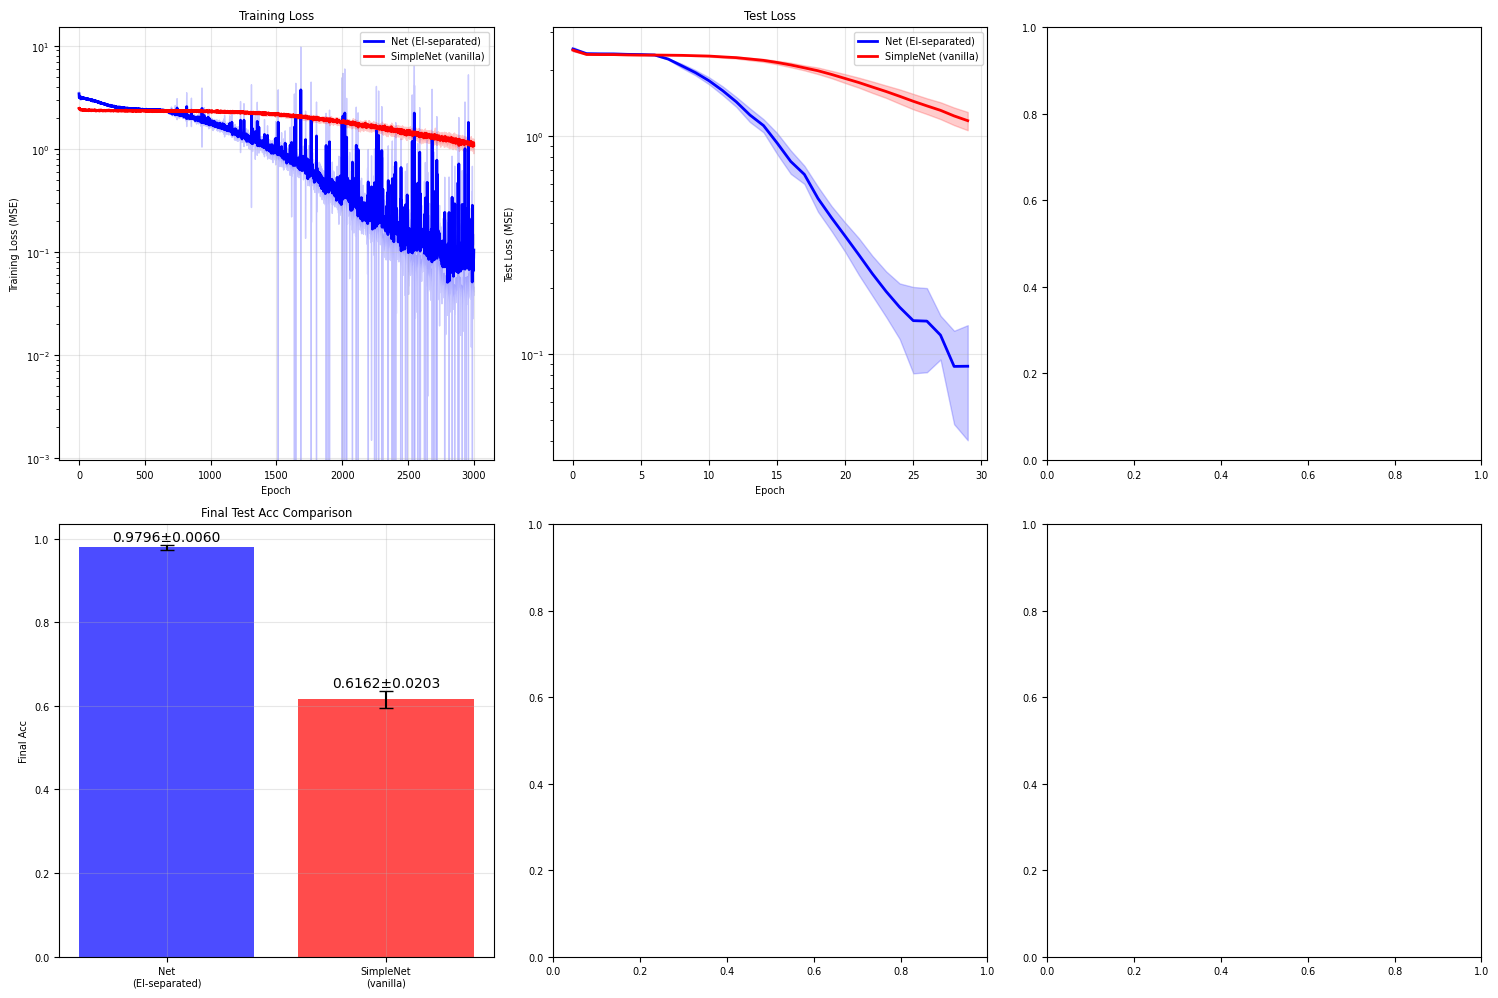

In [6]:
def plot_learning_curves(results, n_seeds):
    """
    Plot learning curves for both models.
    """
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(15, 10))

    # Training loss curves
    net_train_losses = np.array(results['net']['train_losses'])
    simple_train_losses = np.array(results['simple']['train_losses'])

    net_train_mean = np.mean(net_train_losses, axis=0)
    net_train_std = np.std(net_train_losses, axis=0)
    simple_train_mean = np.mean(simple_train_losses, axis=0)
    simple_train_std = np.std(simple_train_losses, axis=0)
    print('net train mean:', net_train_mean)
    print(np.where(net_train_losses>100))

    epochs_range = range(len(net_train_mean))

    ax1.plot(epochs_range, net_train_mean, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.fill_between(epochs_range, net_train_mean - net_train_std, net_train_mean + net_train_std, alpha=0.2, color='blue')
    ax1.plot(epochs_range, simple_train_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.fill_between(epochs_range, simple_train_mean - simple_train_std, simple_train_mean + simple_train_std, alpha=0.2, color='red')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss (MSE)')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')

    # Test loss curves (subset of epochs)
    if results['net']['test_losses'][0] is not None:  # Check if test losses exist
        net_test_losses = np.array(results['net']['test_losses'])
        simple_test_losses = np.array(results['simple']['test_losses'])

        net_test_mean = np.mean(net_test_losses, axis=0)
        net_test_std = np.std(net_test_losses, axis=0)
        simple_test_mean = np.mean(simple_test_losses, axis=0)
        simple_test_std = np.std(simple_test_losses, axis=0)

        test_epochs = range(0, len(net_train_mean))[:len(net_test_mean)]

        ax2.plot(test_epochs, net_test_mean, 'b-', label='Net (EI-separated)', linewidth=2)
        ax2.fill_between(test_epochs, net_test_mean - net_test_std, net_test_mean + net_test_std, alpha=0.2, color='blue')
        ax2.plot(test_epochs, simple_test_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
        ax2.fill_between(test_epochs, simple_test_mean - simple_test_std, simple_test_mean + simple_test_std, alpha=0.2, color='red')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Test Loss (MSE)')
        ax2.set_title('Test Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_yscale('log')


    # Final Acc comparison
    net_acc = results['net']['final_acc']
    simple_acc = results['simple']['final_acc']

    x_pos = [0, 1]
    acc_means = [np.mean(net_acc), np.mean(simple_acc)]
    acc_stds = [np.std(net_acc)/np.sqrt(len(net_acc)), np.std(simple_acc)/np.sqrt(len(simple_acc))]

    bars = ax4.bar(x_pos, acc_means, yerr=acc_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7,
                   label=['Net (EI-separated)', 'SimpleNet (vanilla)'])
    ax4.set_ylabel('Final Acc')
    ax4.set_title('Final Test Acc Comparison')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax4.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, acc_means, acc_stds)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)


    plt.tight_layout()
    plt.show()

# Plot the results
plot_learning_curves(results, n_seeds)

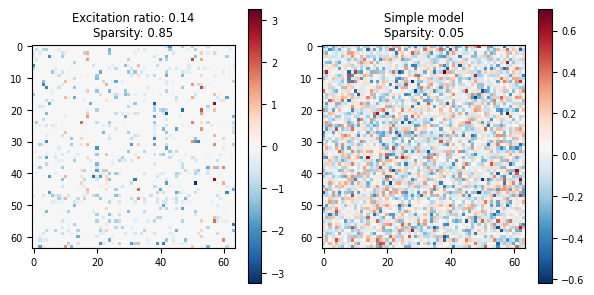

In [7]:
weight = net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
limit = 0.9*max(np.max(weight), np.max(-weight))
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nSparsity: {sparsity:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
im = ax[1].imshow(weight_simple, cmap='RdBu_r')
sparsity_simple = 1 - np.mean(np.abs(weight_simple)>0.1*np.std(np.abs(weight_simple)))
ax[1].set_title(f'Simple model\nSparsity: {sparsity_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()


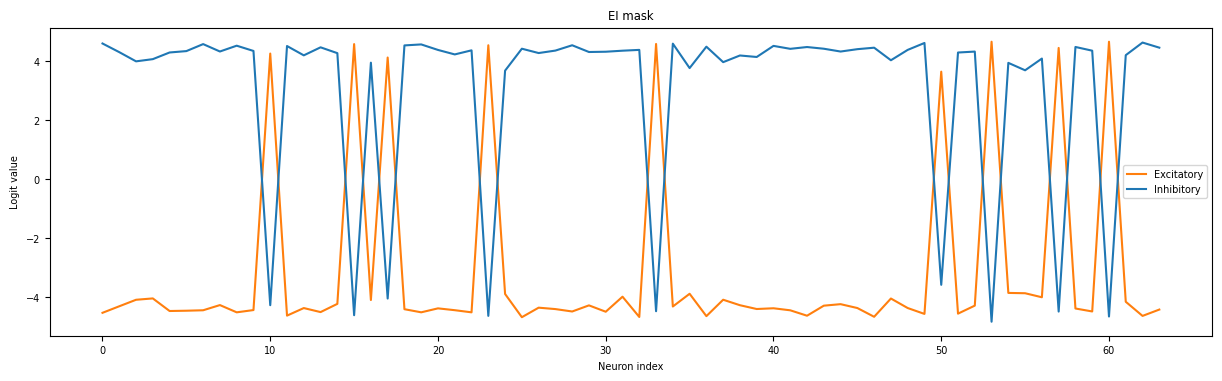

In [8]:
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
ei_code = np.where(eimask[:, 0] > eimask[:, 1], 1., -1.)
mask = np.where(ei_code.reshape(-1,1)>0, np.array([[1,0]]).repeat(eimask.shape[0], axis=0),
                np.array([[0,1]]).repeat(eimask.shape[0], axis=0))
fig, ax = plt.subplots(1,1,figsize=(15, 4))
ax.plot(eimask[:, 0], label='Excitatory', color='C1')
ax.plot(eimask[:, 1], label='Inhibitory', color='C0')
ax.set_title('EI mask')
ax.set_xlabel('Neuron index')
ax.set_ylabel('Logit value')
ax.legend()
plt.show()

In [11]:
# torch.save(net.state_dict(), './model/k-base_computation/ei_net.pth')
# torch.save(simple_net.state_dict(), './model/k-base_computation/simple_net.pth')
config = {'input_size': input_size, 'output_size':output_size,
          'hidden_size': hidden_size, 'epochs': epochs,
          'seq_len': 2}
import json
with open('./model/k-base_computation/model_config.json','w',encoding='utf-8') as f:
    json.dump(config, f, ensure_ascii=False)